In [1]:
import numpy as np
import tensorflow as tf
import tensorflow.keras as keras
import matplotlib.pyplot as plt
import os

In [2]:
# Set Directory
image_path = "./Dataset"
images = []

for filename in os.listdir(image_path):
    img = tf.keras.preprocessing.image.load_img(f"{image_path}/{filename}", target_size=(102,136))
    img = tf.keras.preprocessing.image.img_to_array(img)
    images.append(img)

In [ ]:
# Pre-processing
images = np.array(images).astype(np.float32) / 255.0

x_train = images[:-10] # semua kecuali 10 terakhir
y_train = images[-10:] # 10 images terakhir

In [4]:
# Set constants
BATCH_SIZE = 100
IMAGE_ORIGINAL_SHAPE = x_train.shape[1:] # (102, 136, 3)
IMAGE_SIZE = (
    IMAGE_ORIGINAL_SHAPE[0] * IMAGE_ORIGINAL_SHAPE[1] * IMAGE_ORIGINAL_SHAPE[2]
)
HIDDEN_DIM = 512
LATENT_DIM = 32
MAX_EPOCHS = 10 # Buat di kelas aja, buat hasil bagus ~100
LEARNING_RATE = 0.0001

print(IMAGE_ORIGINAL_SHAPE, IMAGE_SIZE)
# IMAGE_SIZE -> Flatten dari IMAGE_ORIGINAL_SHAPE

(102, 136, 3) 41616


## Model

In [5]:
# ini di lab
# Variational Autoencoder (VAE) Model
class VAE(tf.keras.Model):
    def __init__(self, dim, **kwargs):
        super(VAE, self).__init__(**kwargs)
        h_dim = dim[0] # Hidden Dimension
        z_dim = dim[1] # Latent Dimension

        self.fc1 = tf.keras.layers.Dense(h_dim, activation= tf.nn.relu) # Encoder Features
        self.fc2 = tf.keras.layers.Dense(z_dim) # Cari Mean
        self.fc3 = tf.keras.layers.Dense(z_dim) # Cari Log Variance = standard deviation
        self.fc4 = tf.keras.layers.Dense(h_dim) # Decoder Features
        self.fc5 = tf.keras.layers.Dense(IMAGE_SIZE) # Output
        
        # batch normalization
        self.encoder_batch_norm = tf.keras.layers.BatchNormalization()
        self.decoder_batch_norm = tf.keras.layers.BatchNormalization()

    def encoder(self, x):
        x = self.encoder_batch_norm(x)
        h = self.fc1(x)

        return self.fc2(h), self.fc3(h) # return mean, log variance

    def reparameterize(self, mu, log_var):
        std = tf.exp(log_var * 0.5) # equation for standard deviation
        eps = tf.random.normal(shape=std.shape) # random noise

        return mu + eps * std # equation for reparameterization trick

    def decode_logits(self, z):
        h = self.fc4(z)
        h = self.fc5(h)

        return self.decoder_batch_norm(h) # return logits

    def decode(self, z):
        return tf.nn.sigmoid(self.decode_logits(z)) # return probability

    def call(self, inputs, training=None, mask=None):
        mu, log_var = self.encoder(inputs)
        z = self.reparameterize(mu, log_var)
        x_recon_logits = self.decode(z)

        return x_recon_logits, mu, log_var

In [6]:
# Buat Model
model = VAE((HIDDEN_DIM, LATENT_DIM))
model.build(input_shape=[BATCH_SIZE, IMAGE_SIZE])  # input: (batch, 41616) = 102*136*3 yang di-flatten
dummy_input = tf.zeros((BATCH_SIZE, IMAGE_SIZE))  # dummy input untuk build model
_ = model(dummy_input, training=False)
model.summary()

optimizer = tf.keras.optimizers.Adam(LEARNING_RATE)  # untuk update weights

c:\SEM 5\LAB AI Semester 5\.venv\Lib\site-packages\keras\src\layers\layer.py:431: UserWarning: `build()` was called on layer 'vae', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (100, 512)             │    21,307,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (100, 32)              │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (100, 32)              │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (100, 512)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (100, 41616)           │    21,349,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (100, 41616)           │       166,464 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (100, 41616)           │       166,464 │
│ (BatchNormalization)            │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,039,568 (164.18 MB)

 Trainable params: 42,873,104 (163.55 MB)

 Non-trainable params: 166,464 (650.25 KB)

## Train Model

In [7]:
dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(BATCH_SIZE * 5).batch(BATCH_SIZE)

In [8]:
kl_div_history = []
loss_history = []

m_batches = x_train.shape[0] 

for epoch in range(MAX_EPOCHS):
    for x in dataset:
        with tf.GradientTape() as tape:
            x = tf.reshape(x, [-1, IMAGE_SIZE]) # flatten image
            with tf.GradientTape() as tape:
                # Reconstruction Loss
                x_reconstruction_logits, mu, log_var = model(x)
                reconstruction_loss = tf.nn.sigmoid_cross_entropy_with_logits(labels=x, logits=x_reconstruction_logits)
                reconstruction_loss = tf.reduce_sum(reconstruction_loss) / BATCH_SIZE

                # KL Divergence
                kl_div = -0.5 * tf.reduce_sum(1. + log_var - tf.square(mu) - tf.exp(log_var), axis=-1)
                kl_div = tf.reduce_mean(kl_div)

                # Reconstruction Loss + KL Divergence
                loss = tf.reduce_mean(reconstruction_loss + kl_div)
                gradients = tape.gradient(loss, model.trainable_variables)
                for g in gradients:
                    tf.clip_by_norm(g, 15) # gradient clipping
                
                optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            
            print(f"Epoch: [{epoch+1} / {MAX_EPOCHS}] Reconstruction Loss: {float (reconstruction_loss):.2f} KL Divergence: {float(kl_div):.2f} Total Loss: {float(loss):.2f}")

            kl_div_history.append(float(kl_div))
            loss_history.append(float(loss))

Epoch: [1 / 10] Reconstruction Loss: 24689.98 KL Divergence: 35.28 Total Loss: 24725.26
Epoch: [1 / 10] Reconstruction Loss: 24910.12 KL Divergence: 1144.02 Total Loss: 26054.14
Epoch: [1 / 10] Reconstruction Loss: 24903.22 KL Divergence: 346.95 Total Loss: 25250.17
Epoch: [1 / 10] Reconstruction Loss: 24824.90 KL Divergence: 556.95 Total Loss: 25381.85
Epoch: [1 / 10] Reconstruction Loss: 24588.21 KL Divergence: 631.42 Total Loss: 25219.63
Epoch: [1 / 10] Reconstruction Loss: 24858.26 KL Divergence: 647.55 Total Loss: 25505.81
Epoch: [1 / 10] Reconstruction Loss: 24263.47 KL Divergence: 707.17 Total Loss: 24970.63
Epoch: [1 / 10] Reconstruction Loss: 23633.61 KL Divergence: 728.82 Total Loss: 24362.43
Epoch: [1 / 10] Reconstruction Loss: 23806.71 KL Divergence: 685.82 Total Loss: 24492.53
Epoch: [1 / 10] Reconstruction Loss: 23586.72 KL Divergence: 681.40 Total Loss: 24268.12
Epoch: [1 / 10] Reconstruction Loss: 23837.52 KL Divergence: 629.01 Total Loss: 24466.53
Epoch: [1 / 10] Recon

Text(0, 0.5, 'KL Divergence')

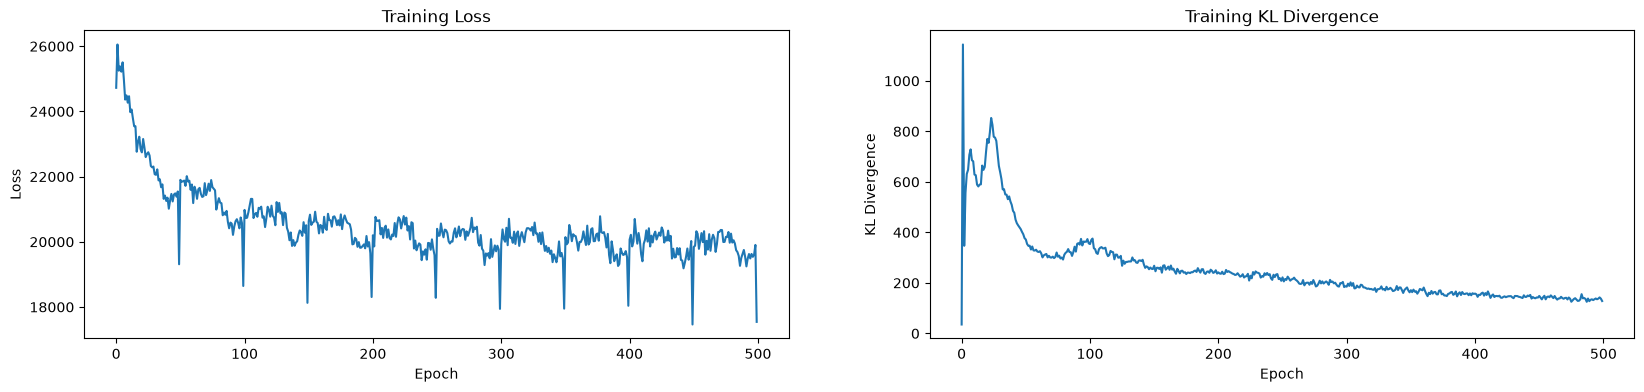

In [9]:
# Plotting hasil
plt.figure(figsize=(20, 4))
plt.subplot(1, 2, 1)
plt.plot(loss_history)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(kl_div_history)
plt.title('Training KL Divergence')
plt.xlabel('Epoch')
plt.ylabel('KL Divergence')

In [11]:
z = tf.random.normal((BATCH_SIZE, LATENT_DIM)) # titik awal rekonstruksi
out = model.decode(z) # hasil rekonstruksi
out = tf.reshape(out, [-1, IMAGE_ORIGINAL_SHAPE[0], IMAGE_ORIGINAL_SHAPE[1], IMAGE_ORIGINAL_SHAPE[2]]).numpy() * 255
out = out.astype(np.uint8)

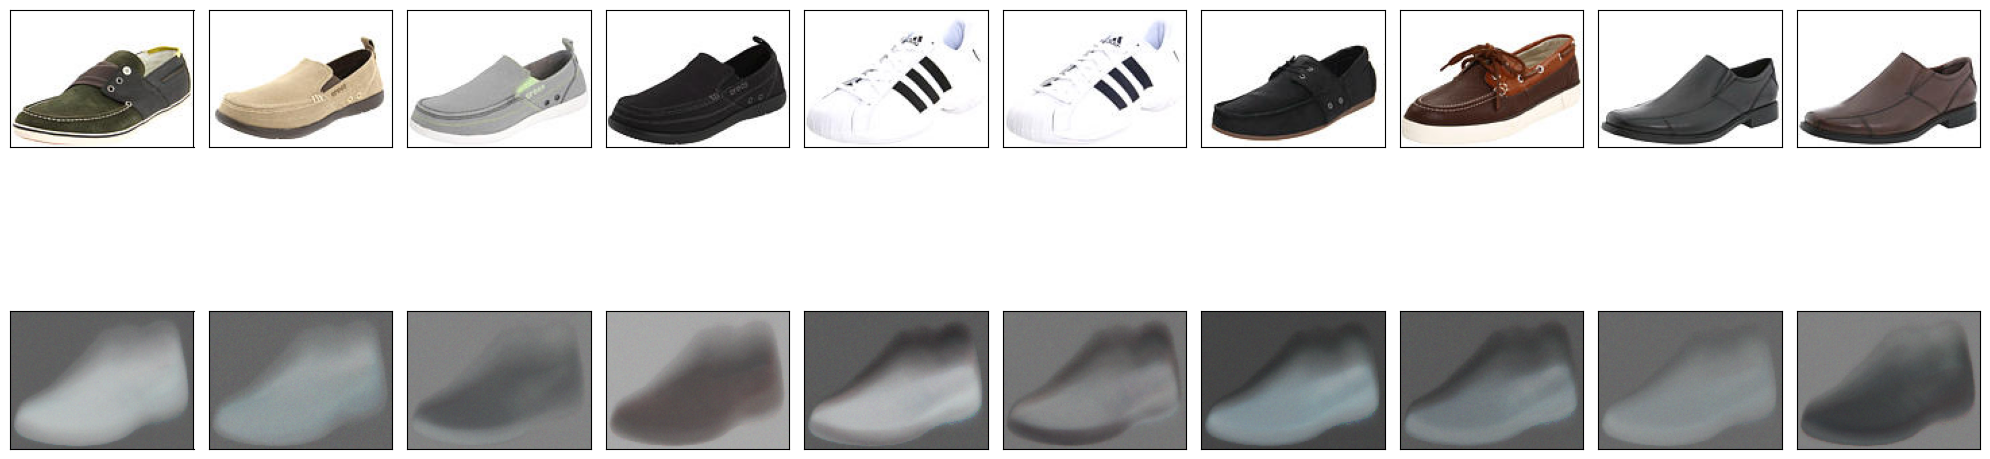

In [12]:
# Reconstruct image
number = 10
plt.figure(figsize=(20, 8))
for index in range(number):
    ax = plt.subplot(2, number, index + 1)
    plt.imshow(y_train[index].reshape(IMAGE_ORIGINAL_SHAPE), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

for index in range(number):
    ax = plt.subplot(2, number, index + 1 + number)
    plt.imshow(out[index].reshape(IMAGE_ORIGINAL_SHAPE), cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()
